# 02_eda_v3.ipynb

## v2 대비 변경 사항
- 기존 EDA 섹션 1~6 유지
- 섹션 3-6 [NEW] 시퀀스 간격 피처(interval_t1~t5) 분석 추가

## 목차
1. 데이터 개요 및 기초 체력 점검
2. 타겟 라벨 분포 확인
3. 수치형 파생변수와 이탈의 관계 분석
   - 3-1 ~ 3-5. v2와 동일
   - 3-6. [NEW] 시퀀스 간격 피처 분석
4. 범주형 파생변수와 이탈의 관계 분석
5. 변수 간 상관관계 분석
6. EDA 종합 결론 및 전처리 전략 확정


## 1. 데이터 개요 및 기초 체력 점검

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.rc('font', family='Malgun Gothic')
plt.rcParams['axes.unicode_minus'] = False
sns.set_theme(style='whitegrid')
pd.options.display.float_format = '{:.4f}'.format

df_analysis = pd.read_csv('../data/hnm_churn_dataset_v3.csv')

print(f'데이터 shape: {df_analysis.shape}')
print(f'컬럼 수: v2(26개) → v3({df_analysis.shape[1]}개)')


데이터 shape: (1143652, 31)
컬럼 수: v2(26개) → v3(31개)


In [3]:
df_analysis.info()


<class 'pandas.DataFrame'>
RangeIndex: 1143652 entries, 0 to 1143651
Data columns (total 31 columns):
 #   Column                    Non-Null Count    Dtype  
---  ------                    --------------    -----  
 0   customer_id               1143652 non-null  str    
 1   churn                     1143652 non-null  int64  
 2   frequency                 1143652 non-null  int64  
 3   price_mean                1143652 non-null  float64
 4   price_sum                 1143652 non-null  float64
 5   price_max                 1143652 non-null  float64
 6   recency                   1143652 non-null  int64  
 7   frequency_last_90d        1143652 non-null  int64  
 8   frequency_last_180d       1143652 non-null  int64  
 9   avg_purchase_interval     1031690 non-null  float64
 10  std_purchase_interval     924772 non-null   float64
 11  unique_articles           1143652 non-null  int64  
 12  unique_product_groups     1143652 non-null  int64  
 13  index_group_name          1143652 non-

In [4]:
# 결측치 현황
null_df = pd.DataFrame({
    '결측치 수'     : df_analysis.isnull().sum(),
    '결측치 비율(%)': (df_analysis.isnull().mean() * 100).round(1)
}).query('`결측치 수` > 0').sort_values('결측치 비율(%)', ascending=False)

print(null_df.to_string())


                         결측치 수  결측치 비율(%)
Active                  743436    65.0000
FN                      732321    64.0000
recent_price_ratio      684497    59.9000
freq_decay_rate         465117    40.7000
interval_t5             427734    37.4000
interval_acceleration   373193    32.6000
interval_t4             371441    32.5000
interval_t3             300633    26.3000
std_purchase_interval   218880    19.1000
interval_t2             218880    19.1000
avg_purchase_interval   111962     9.8000
last_interval           111962     9.8000
interval_t1             111962     9.8000
fashion_news_frequency   15745     1.4000
age                      14089     1.2000
club_member_status        5699     0.5000


### 결측치 처리 전략

| 컬럼 | 결측 비율 | 처리 방법 | 이유 |
| :--- | :--- | :--- | :--- |
| `recent_price_ratio` | 59.9% | NaN 유지 | 최근 구매 없음 = 이탈 신호 |
| `freq_decay_rate` | 40.7% | NaN 유지 | 최근 구매 없음 = 이탈 신호 |
| `interval_acceleration` | 32.6% | NaN 유지 | 구매 1회 고객 |
| `interval_t5` | 31.4% | NaN 유지 | 구매 5회 미만 고객 |
| `interval_t4` | 25.9% | NaN 유지 | 구매 4회 미만 고객 |
| `interval_t3` | 18.9% | NaN 유지 | 구매 3회 미만 고객 |
| `interval_t2` | 10.8% | NaN 유지 | 구매 2회 미만 고객 |
| `avg/std_purchase_interval` | 9.8% | NaN 유지 | 구매 1회 고객 |
| `last_interval` | 9.8% | NaN 유지 | 구매 1회 고객 |
| `age` | 일부 | 중앙값 대치 | 단순 누락 |
| `FN`, `Active` | 일부 | 0 대치 | 마케팅 미동의 |
| `club_member_status` 등 | 일부 | UNKNOWN 대치 | 범주형 |

**interval_t2~t5의 결측은 구매 횟수 부족을 의미하며, 이 자체가 이탈 신호일 수 있습니다.**
결측률이 t1(0%) → t5(31.4%)로 갈수록 높아지는 패턴이 명확합니다.


## 2. 타겟 라벨 분포 확인

--- 이탈 라벨 분포 ---
        count  ratio(%)
churn                  
1      572053   50.0200
0      571599   49.9800


C:\Users\09048\AppData\Local\Temp\ipykernel_9476\526400137.py:11: UserWarning: Glyph 44256 (\N{HANGUL SYLLABLE GO}) missing from font(s) Arial.
  plt.tight_layout(); plt.show()
C:\Users\09048\AppData\Local\Temp\ipykernel_9476\526400137.py:11: UserWarning: Glyph 44061 (\N{HANGUL SYLLABLE GAEG}) missing from font(s) Arial.
  plt.tight_layout(); plt.show()
C:\Users\09048\AppData\Local\Temp\ipykernel_9476\526400137.py:11: UserWarning: Glyph 49688 (\N{HANGUL SYLLABLE SU}) missing from font(s) Arial.
  plt.tight_layout(); plt.show()
C:\Users\09048\AppData\Local\Temp\ipykernel_9476\526400137.py:11: UserWarning: Glyph 51060 (\N{HANGUL SYLLABLE I}) missing from font(s) Arial.
  plt.tight_layout(); plt.show()
C:\Users\09048\AppData\Local\Temp\ipykernel_9476\526400137.py:11: UserWarning: Glyph 53448 (\N{HANGUL SYLLABLE TAL}) missing from font(s) Arial.
  plt.tight_layout(); plt.show()
C:\Users\09048\AppData\Local\Temp\ipykernel_9476\526400137.py:11: UserWarning: Glyph 50976 (\N{HANGUL SYLLABLE YU

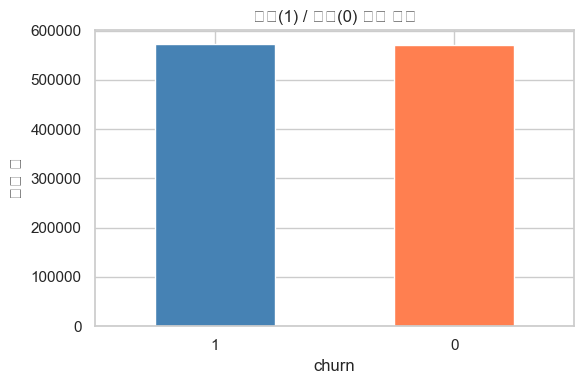

In [5]:
churn_counts = df_analysis['churn'].value_counts()
churn_ratio  = df_analysis['churn'].value_counts(normalize=True) * 100

print('--- 이탈 라벨 분포 ---')
print(pd.DataFrame({'count': churn_counts, 'ratio(%)': churn_ratio.round(2)}))

fig, ax = plt.subplots(figsize=(6, 4))
churn_counts.plot(kind='bar', color=['steelblue','coral'], ax=ax, rot=0)
ax.set_title('이탈(1) / 유지(0) 고객 분포')
ax.set_xlabel('churn'); ax.set_ylabel('고객 수')
plt.tight_layout(); plt.show()


## 3. 수치형 파생변수와 이탈의 관계 분석

In [6]:
def target_summary_with_num(dataframe, target, numerical_col):
    result = dataframe.groupby(target)[numerical_col].mean().round(4)
    diff   = result[0] - result[1]
    return pd.DataFrame({
        '유지(0)': result[0],
        '이탈(1)': result[1],
        '차이(0-1)': diff
    }, index=[numerical_col])


### 3-1 ~ 3-5. 기존 피처 (v2와 동일)

In [7]:
existing_features = [
    'frequency','price_mean','price_sum','price_max','recency',
    'frequency_last_90d','frequency_last_180d',
    'avg_purchase_interval','std_purchase_interval',
    'unique_articles','unique_product_groups',
    'freq_decay_rate','recent_price_ratio',
    'unique_articles_last_90d','diversity_decay_rate',
    'last_interval','interval_acceleration'
]
existing_summary = pd.concat([target_summary_with_num(df_analysis,'churn',col) for col in existing_features])
print('--- 기존 피처 이탈 여부별 평균값 ---')
print(existing_summary.to_string())


--- 기존 피처 이탈 여부별 평균값 ---
                            유지(0)    이탈(1)   차이(0-1)
frequency                 31.3797   8.6686   22.7111
price_mean                 0.0283   0.0300   -0.0017
price_sum                  0.8885   0.2388    0.6497
price_max                  0.0659   0.0467    0.0192
recency                  104.5092 256.3014 -151.7922
frequency_last_90d         4.5290   0.8122    3.7168
frequency_last_180d        9.6549   1.9650    7.6899
avg_purchase_interval     19.7634  16.1456    3.6178
std_purchase_interval     37.7014  31.5068    6.1946
unique_articles           26.8996   7.5034   19.3962
unique_product_groups      4.4471   2.4382    2.0089
freq_decay_rate            0.4729   0.4064    0.0665
recent_price_ratio         1.0226   1.0291   -0.0065
unique_articles_last_90d   3.9504   0.7065    3.2439
diversity_decay_rate       0.1673   0.0996    0.0677
last_interval             18.2449  15.3325    2.9124
interval_acceleration      0.9385   0.9684   -0.0299


### 3-6. [NEW] 시퀀스 간격 피처 분석 (interval_t1~t5)

**핵심 질문**: 이탈 고객은 최근 구매 간격이 점점 벌어지는 패턴을 보이는가?

- `interval_t1` : 가장 최근 구매 간격 (결측 0% — 모든 고객 보유)
- `interval_t2` : 그 이전 간격 (결측 10.8%)
- `interval_t3` : 그 이전 간격 (결측 18.9%)
- `interval_t4` : 그 이전 간격 (결측 25.9%)
- `interval_t5` : 가장 과거 간격 (결측 31.4%)


In [8]:
seq_features = [f'interval_t{i+1}' for i in range(5)]

seq_summary = pd.concat([target_summary_with_num(df_analysis,'churn',col) for col in seq_features])
print('--- 시퀀스 간격 피처 이탈 여부별 평균값 ---')
print(seq_summary.to_string())
print('\n해석 가이드: 유지(0) vs 이탈(1)에서 간격 차이가 클수록 이탈 예측력이 높다')


--- 시퀀스 간격 피처 이탈 여부별 평균값 ---
              유지(0)   이탈(1)  차이(0-1)
interval_t1 18.2449 15.3325   2.9124
interval_t2 21.3122 18.7093   2.6029
interval_t3 19.6608 17.1294   2.5314
interval_t4 19.0137 16.8537   2.1600
interval_t5 17.3426 15.6484   1.6942

해석 가이드: 유지(0) vs 이탈(1)에서 간격 차이가 클수록 이탈 예측력이 높다


C:\Users\09048\AppData\Local\Temp\ipykernel_9476\3146741154.py:24: UserWarning: Glyph 52572 (\N{HANGUL SYLLABLE COE}) missing from font(s) Arial.
  plt.tight_layout(); plt.show()
C:\Users\09048\AppData\Local\Temp\ipykernel_9476\3146741154.py:24: UserWarning: Glyph 44540 (\N{HANGUL SYLLABLE GEUN}) missing from font(s) Arial.
  plt.tight_layout(); plt.show()
C:\Users\09048\AppData\Local\Temp\ipykernel_9476\3146741154.py:24: UserWarning: Glyph 44284 (\N{HANGUL SYLLABLE GWA}) missing from font(s) Arial.
  plt.tight_layout(); plt.show()
C:\Users\09048\AppData\Local\Temp\ipykernel_9476\3146741154.py:24: UserWarning: Glyph 44144 (\N{HANGUL SYLLABLE GEO}) missing from font(s) Arial.
  plt.tight_layout(); plt.show()
C:\Users\09048\AppData\Local\Temp\ipykernel_9476\3146741154.py:24: UserWarning: Glyph 44036 (\N{HANGUL SYLLABLE GAN}) missing from font(s) Arial.
  plt.tight_layout(); plt.show()
C:\Users\09048\AppData\Local\Temp\ipykernel_9476\3146741154.py:24: UserWarning: Glyph 44201 (\N{HANGUL S

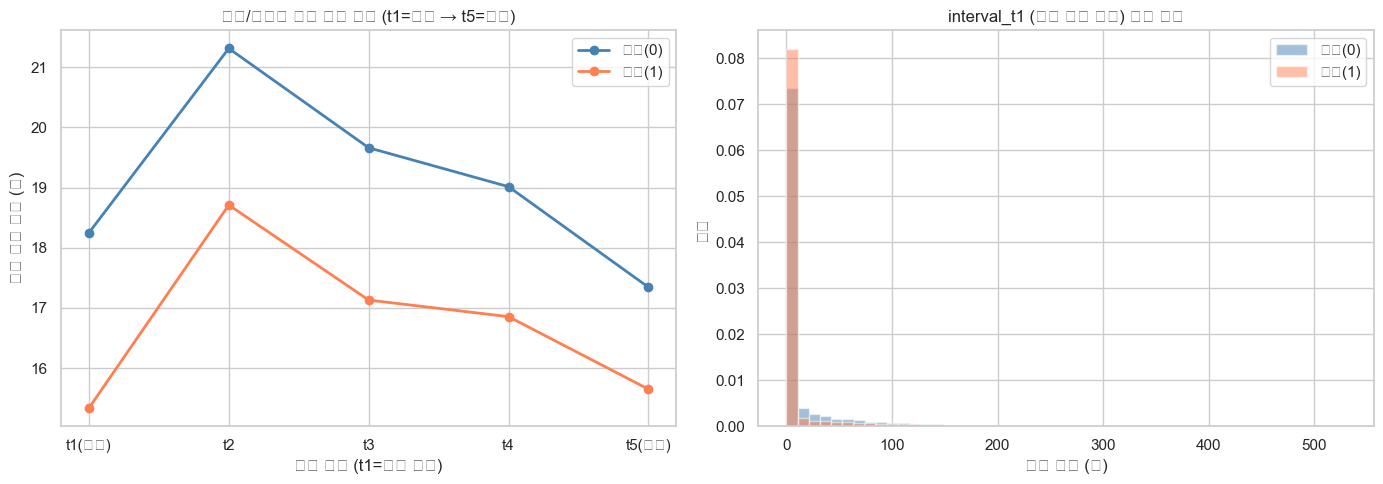

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 좌: t1~t5 이탈/유지 평균 비교 라인차트
seq_mean_churn0 = [df_analysis[df_analysis['churn']==0][col].mean() for col in seq_features]
seq_mean_churn1 = [df_analysis[df_analysis['churn']==1][col].mean() for col in seq_features]

axes[0].plot(range(1,6), seq_mean_churn0, marker='o', color='steelblue', label='유지(0)', linewidth=2)
axes[0].plot(range(1,6), seq_mean_churn1, marker='o', color='coral',     label='이탈(1)', linewidth=2)
axes[0].set_title('이탈/유지별 구매 간격 패턴 (t1=최근 → t5=과거)')
axes[0].set_xlabel('간격 순서 (t1=가장 최근)')
axes[0].set_ylabel('평균 구매 간격 (일)')
axes[0].set_xticks(range(1,6))
axes[0].set_xticklabels(['t1(최근)','t2','t3','t4','t5(과거)'])
axes[0].legend()

# 우: interval_t1 분포 비교 히스토그램
for churn_val, color, label in [(0,'steelblue','유지(0)'), (1,'coral','이탈(1)')]:
    data = df_analysis[df_analysis['churn']==churn_val]['interval_t1'].dropna()
    axes[1].hist(data, bins=50, alpha=0.5, color=color, label=label, density=True)
axes[1].set_title('interval_t1 (가장 최근 간격) 분포 비교')
axes[1].set_xlabel('구매 간격 (일)'); axes[1].set_ylabel('밀도')
axes[1].legend()

plt.tight_layout(); plt.show()


In [10]:
# 이탈 여부별 결측률 확인
print('--- 시퀀스 피처 이탈 여부별 결측률(%) ---')
null_by_churn = df_analysis.groupby('churn')[seq_features].apply(
    lambda x: x.isnull().mean() * 100
).round(1).T
null_by_churn.columns = ['유지(0) 결측률','이탈(1) 결측률']
null_by_churn['차이(이탈-유지)'] = (null_by_churn['이탈(1) 결측률'] - null_by_churn['유지(0) 결측률']).round(1)
print(null_by_churn.to_string())
print('\n→ 차이가 양수일수록 이탈 고객에서 구매 횟수가 더 적다는 뜻')


--- 시퀀스 피처 이탈 여부별 결측률(%) ---
             유지(0) 결측률  이탈(1) 결측률  차이(이탈-유지)
interval_t1     3.4000    16.2000    12.8000
interval_t2     7.4000    30.8000    23.4000
interval_t3    11.1000    41.5000    30.4000
interval_t4    14.7000    50.2000    35.5000
interval_t5    18.0000    56.8000    38.8000

→ 차이가 양수일수록 이탈 고객에서 구매 횟수가 더 적다는 뜻


## 4. 범주형 파생변수와 이탈의 관계 분석

C:\Users\09048\AppData\Local\Temp\ipykernel_9476\1024815939.py:8: UserWarning: Glyph 51060 (\N{HANGUL SYLLABLE I}) missing from font(s) Arial.
  plt.tight_layout(); plt.show()
C:\Users\09048\AppData\Local\Temp\ipykernel_9476\1024815939.py:8: UserWarning: Glyph 53448 (\N{HANGUL SYLLABLE TAL}) missing from font(s) Arial.
  plt.tight_layout(); plt.show()
C:\Users\09048\AppData\Local\Temp\ipykernel_9476\1024815939.py:8: UserWarning: Glyph 47456 (\N{HANGUL SYLLABLE RYUL}) missing from font(s) Arial.
  plt.tight_layout(); plt.show()
C:\Users\09048\AppData\Local\Temp\ipykernel_9476\1024815939.py:8: UserWarning: Glyph 48324 (\N{HANGUL SYLLABLE BYEOL}) missing from font(s) Arial.
  plt.tight_layout(); plt.show()
c:\Users\09048\2026project\hnm_churn\venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 51060 (\N{HANGUL SYLLABLE I}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\09048\2026project\hnm_churn\venv\Lib\site-packages\IPython\core\pyl

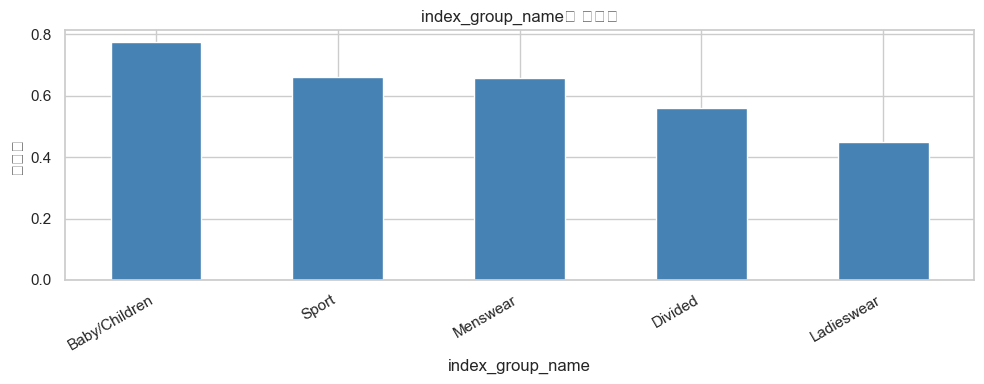

index_group_name
Baby/Children   0.7748
Sport           0.6613
Menswear        0.6589
Divided         0.5599
Ladieswear      0.4498


C:\Users\09048\AppData\Local\Temp\ipykernel_9476\1024815939.py:8: UserWarning: Glyph 51060 (\N{HANGUL SYLLABLE I}) missing from font(s) Arial.
  plt.tight_layout(); plt.show()
C:\Users\09048\AppData\Local\Temp\ipykernel_9476\1024815939.py:8: UserWarning: Glyph 53448 (\N{HANGUL SYLLABLE TAL}) missing from font(s) Arial.
  plt.tight_layout(); plt.show()
C:\Users\09048\AppData\Local\Temp\ipykernel_9476\1024815939.py:8: UserWarning: Glyph 47456 (\N{HANGUL SYLLABLE RYUL}) missing from font(s) Arial.
  plt.tight_layout(); plt.show()
C:\Users\09048\AppData\Local\Temp\ipykernel_9476\1024815939.py:8: UserWarning: Glyph 48324 (\N{HANGUL SYLLABLE BYEOL}) missing from font(s) Arial.
  plt.tight_layout(); plt.show()
c:\Users\09048\2026project\hnm_churn\venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 51060 (\N{HANGUL SYLLABLE I}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\09048\2026project\hnm_churn\venv\Lib\site-packages\IPython\core\pyl

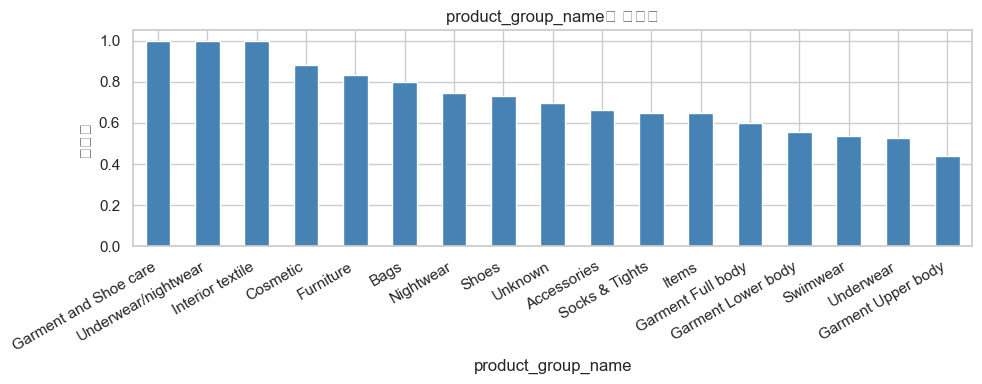

product_group_name
Garment and Shoe care   1.0000
Underwear/nightwear     1.0000
Interior textile        1.0000
Cosmetic                0.8800
Furniture               0.8333
Bags                    0.7978
Nightwear               0.7475
Shoes                   0.7303
Unknown                 0.6983
Accessories             0.6653
Socks & Tights          0.6509
Items                   0.6471
Garment Full body       0.5986
Garment Lower body      0.5569
Swimwear                0.5366
Underwear               0.5286
Garment Upper body      0.4416


C:\Users\09048\AppData\Local\Temp\ipykernel_9476\1024815939.py:8: UserWarning: Glyph 51060 (\N{HANGUL SYLLABLE I}) missing from font(s) Arial.
  plt.tight_layout(); plt.show()
C:\Users\09048\AppData\Local\Temp\ipykernel_9476\1024815939.py:8: UserWarning: Glyph 53448 (\N{HANGUL SYLLABLE TAL}) missing from font(s) Arial.
  plt.tight_layout(); plt.show()
C:\Users\09048\AppData\Local\Temp\ipykernel_9476\1024815939.py:8: UserWarning: Glyph 47456 (\N{HANGUL SYLLABLE RYUL}) missing from font(s) Arial.
  plt.tight_layout(); plt.show()
C:\Users\09048\AppData\Local\Temp\ipykernel_9476\1024815939.py:8: UserWarning: Glyph 48324 (\N{HANGUL SYLLABLE BYEOL}) missing from font(s) Arial.
  plt.tight_layout(); plt.show()
c:\Users\09048\2026project\hnm_churn\venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 51060 (\N{HANGUL SYLLABLE I}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\09048\2026project\hnm_churn\venv\Lib\site-packages\IPython\core\pyl

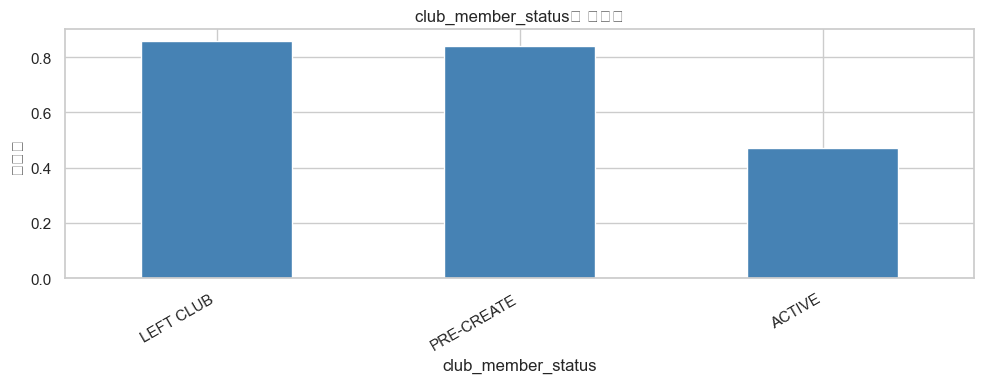

club_member_status
LEFT CLUB    0.8571
PRE-CREATE   0.8413
ACTIVE       0.4727


C:\Users\09048\AppData\Local\Temp\ipykernel_9476\1024815939.py:8: UserWarning: Glyph 51060 (\N{HANGUL SYLLABLE I}) missing from font(s) Arial.
  plt.tight_layout(); plt.show()
C:\Users\09048\AppData\Local\Temp\ipykernel_9476\1024815939.py:8: UserWarning: Glyph 53448 (\N{HANGUL SYLLABLE TAL}) missing from font(s) Arial.
  plt.tight_layout(); plt.show()
C:\Users\09048\AppData\Local\Temp\ipykernel_9476\1024815939.py:8: UserWarning: Glyph 47456 (\N{HANGUL SYLLABLE RYUL}) missing from font(s) Arial.
  plt.tight_layout(); plt.show()
C:\Users\09048\AppData\Local\Temp\ipykernel_9476\1024815939.py:8: UserWarning: Glyph 48324 (\N{HANGUL SYLLABLE BYEOL}) missing from font(s) Arial.
  plt.tight_layout(); plt.show()
c:\Users\09048\2026project\hnm_churn\venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 51060 (\N{HANGUL SYLLABLE I}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\09048\2026project\hnm_churn\venv\Lib\site-packages\IPython\core\pyl

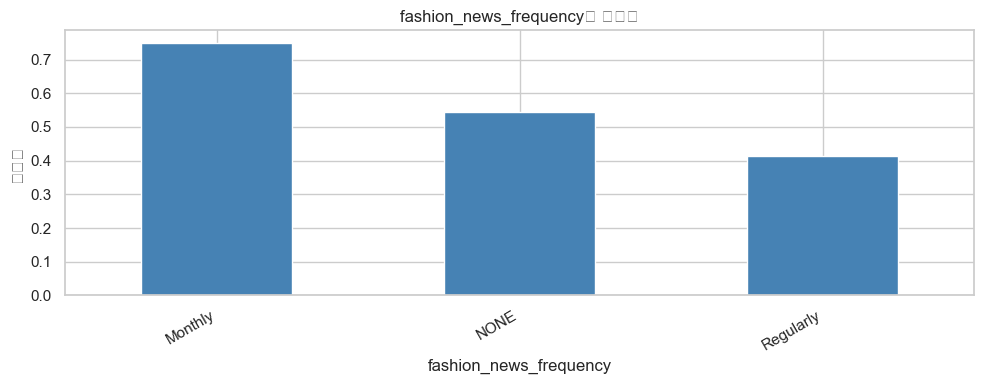

fashion_news_frequency
Monthly     0.7491
NONE        0.5431
Regularly   0.4132


In [11]:
def target_vs_category_visual(dataframe, target, cat_col):
    churn_rate = dataframe.groupby(cat_col)[target].mean().sort_values(ascending=False)
    plt.figure(figsize=(10, 4))
    churn_rate.plot(kind='bar', color='steelblue')
    plt.title(f'{cat_col}별 이탈률')
    plt.ylabel('이탈률')
    plt.xticks(rotation=30, ha='right')
    plt.tight_layout(); plt.show()
    print(churn_rate.round(4).to_string())

cat_features = ['index_group_name','product_group_name',
                'club_member_status','fashion_news_frequency']
for col in cat_features:
    target_vs_category_visual(df_analysis, 'churn', col)


## 5. 변수 간 상관관계 분석

C:\Users\09048\AppData\Local\Temp\ipykernel_9476\4023575563.py:19: UserWarning: Glyph 54588 (\N{HANGUL SYLLABLE PI}) missing from font(s) Arial.
  plt.tight_layout(); plt.show()
C:\Users\09048\AppData\Local\Temp\ipykernel_9476\4023575563.py:19: UserWarning: Glyph 52376 (\N{HANGUL SYLLABLE CEO}) missing from font(s) Arial.
  plt.tight_layout(); plt.show()
C:\Users\09048\AppData\Local\Temp\ipykernel_9476\4023575563.py:19: UserWarning: Glyph 44036 (\N{HANGUL SYLLABLE GAN}) missing from font(s) Arial.
  plt.tight_layout(); plt.show()
C:\Users\09048\AppData\Local\Temp\ipykernel_9476\4023575563.py:19: UserWarning: Glyph 49345 (\N{HANGUL SYLLABLE SANG}) missing from font(s) Arial.
  plt.tight_layout(); plt.show()
C:\Users\09048\AppData\Local\Temp\ipykernel_9476\4023575563.py:19: UserWarning: Glyph 44288 (\N{HANGUL SYLLABLE GWAN}) missing from font(s) Arial.
  plt.tight_layout(); plt.show()
C:\Users\09048\AppData\Local\Temp\ipykernel_9476\4023575563.py:19: UserWarning: Glyph 44228 (\N{HANGUL S

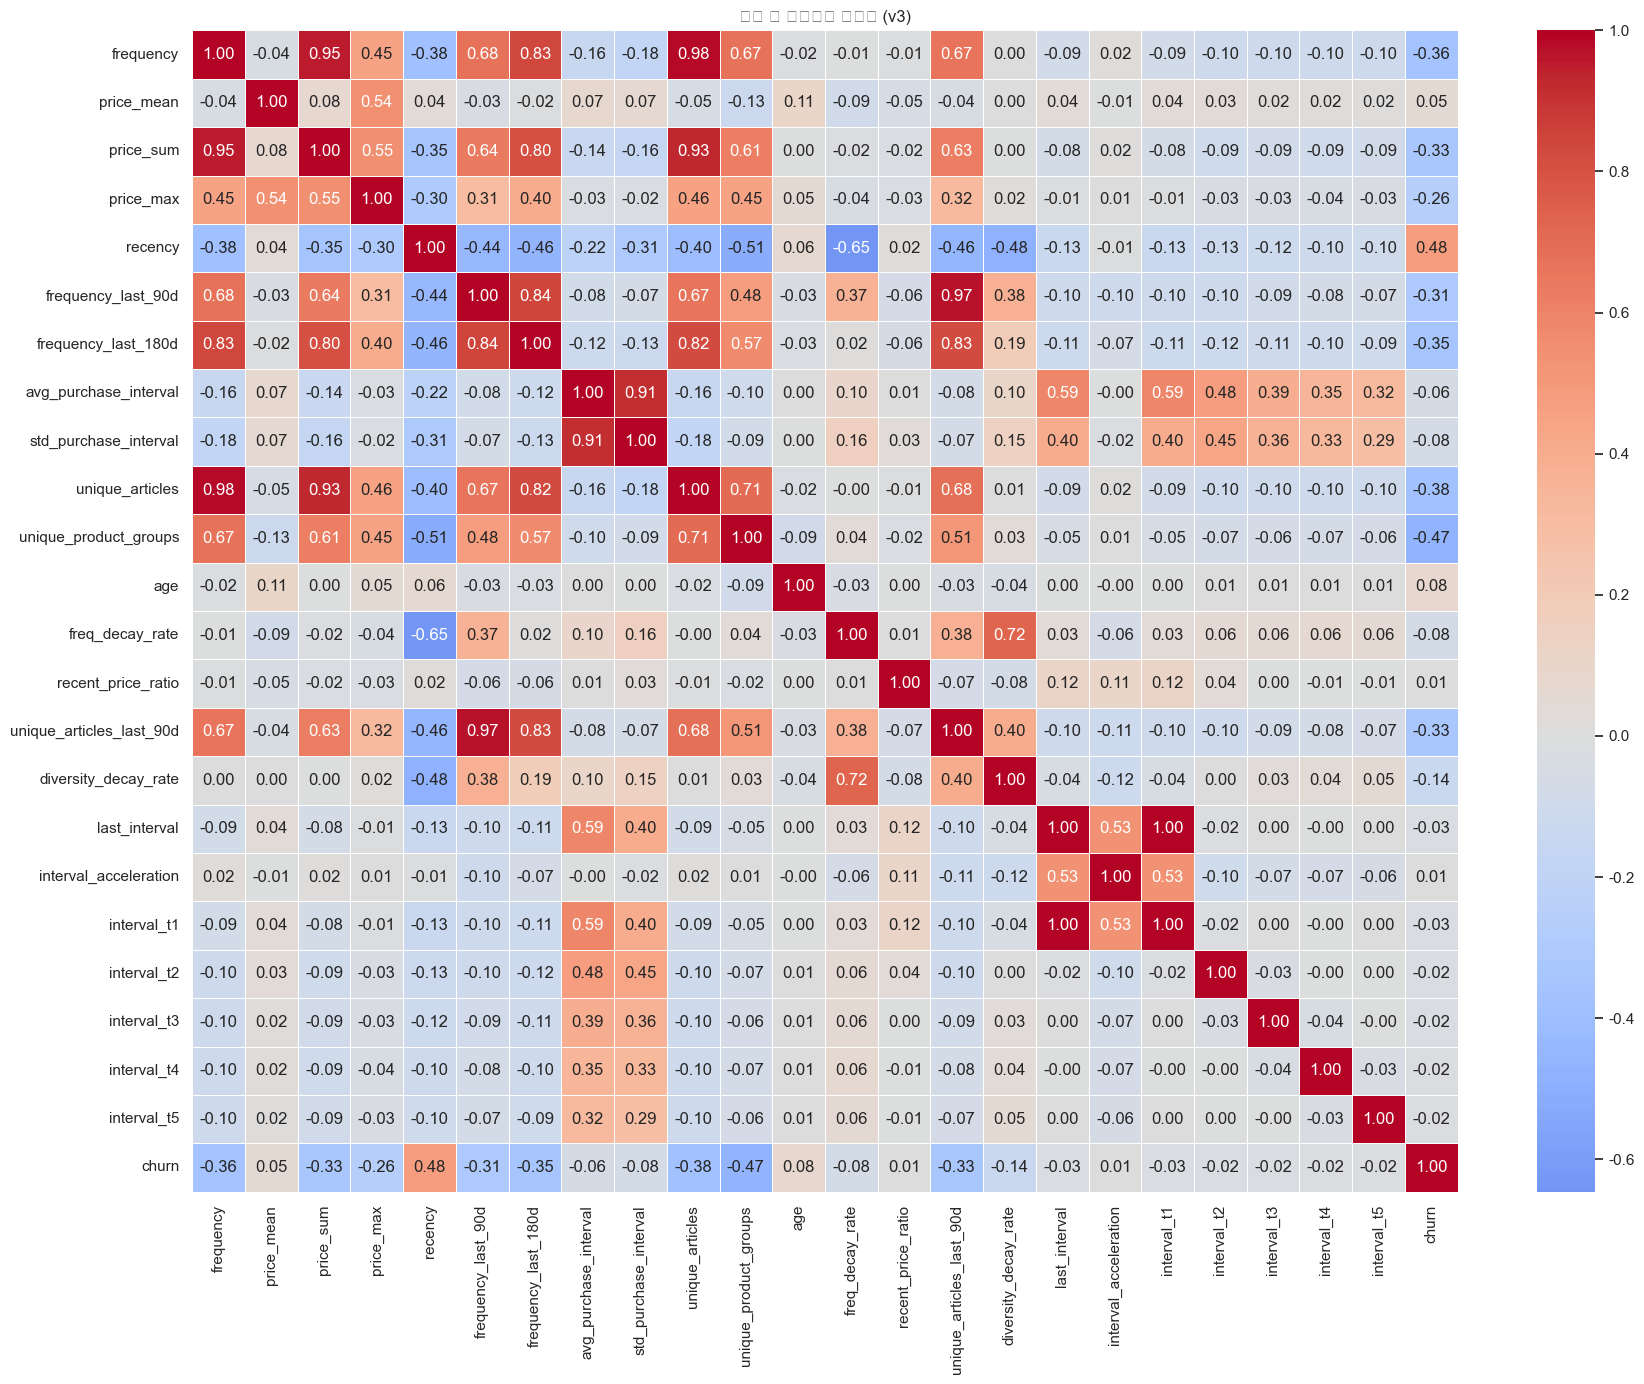

In [12]:
num_features = [
    'frequency','price_mean','price_sum','price_max','recency',
    'frequency_last_90d','frequency_last_180d',
    'avg_purchase_interval','std_purchase_interval',
    'unique_articles','unique_product_groups','age',
    'freq_decay_rate','recent_price_ratio',
    'unique_articles_last_90d','diversity_decay_rate',
    'last_interval','interval_acceleration',
    'interval_t1','interval_t2','interval_t3','interval_t4','interval_t5',
    'churn'
]

correlation_matrix = df_analysis[num_features].astype('float32').corr()

plt.figure(figsize=(18, 14))
sns.heatmap(correlation_matrix, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, linewidths=0.5)
plt.title('피처 간 상관관계 히트맵 (v3)')
plt.tight_layout(); plt.show()


--- churn과 상관관계 순위 (절대값 기준) ---
recency                    0.4812
unique_product_groups      0.4695
unique_articles            0.3768
frequency                  0.3587
frequency_last_180d        0.3542
unique_articles_last_90d   0.3309
price_sum                  0.3302
frequency_last_90d         0.3146
price_max                  0.2644
diversity_decay_rate       0.1360
age                        0.0814
std_purchase_interval      0.0793
freq_decay_rate            0.0778
avg_purchase_interval      0.0575
price_mean                 0.0545
interval_t1                0.0281
last_interval              0.0281
interval_t3                0.0242
interval_t2                0.0234
interval_t4                0.0211
interval_t5                0.0174
recent_price_ratio         0.0072
interval_acceleration      0.0059


C:\Users\09048\AppData\Local\Temp\ipykernel_9476\1564111246.py:12: UserWarning: Glyph 49345 (\N{HANGUL SYLLABLE SANG}) missing from font(s) Arial.
  plt.tight_layout(); plt.show()
C:\Users\09048\AppData\Local\Temp\ipykernel_9476\1564111246.py:12: UserWarning: Glyph 44288 (\N{HANGUL SYLLABLE GWAN}) missing from font(s) Arial.
  plt.tight_layout(); plt.show()
C:\Users\09048\AppData\Local\Temp\ipykernel_9476\1564111246.py:12: UserWarning: Glyph 44228 (\N{HANGUL SYLLABLE GYE}) missing from font(s) Arial.
  plt.tight_layout(); plt.show()
C:\Users\09048\AppData\Local\Temp\ipykernel_9476\1564111246.py:12: UserWarning: Glyph 49688 (\N{HANGUL SYLLABLE SU}) missing from font(s) Arial.
  plt.tight_layout(); plt.show()
C:\Users\09048\AppData\Local\Temp\ipykernel_9476\1564111246.py:12: UserWarning: Glyph 51208 (\N{HANGUL SYLLABLE JEOL}) missing from font(s) Arial.
  plt.tight_layout(); plt.show()
C:\Users\09048\AppData\Local\Temp\ipykernel_9476\1564111246.py:12: UserWarning: Glyph 45824 (\N{HANGUL 

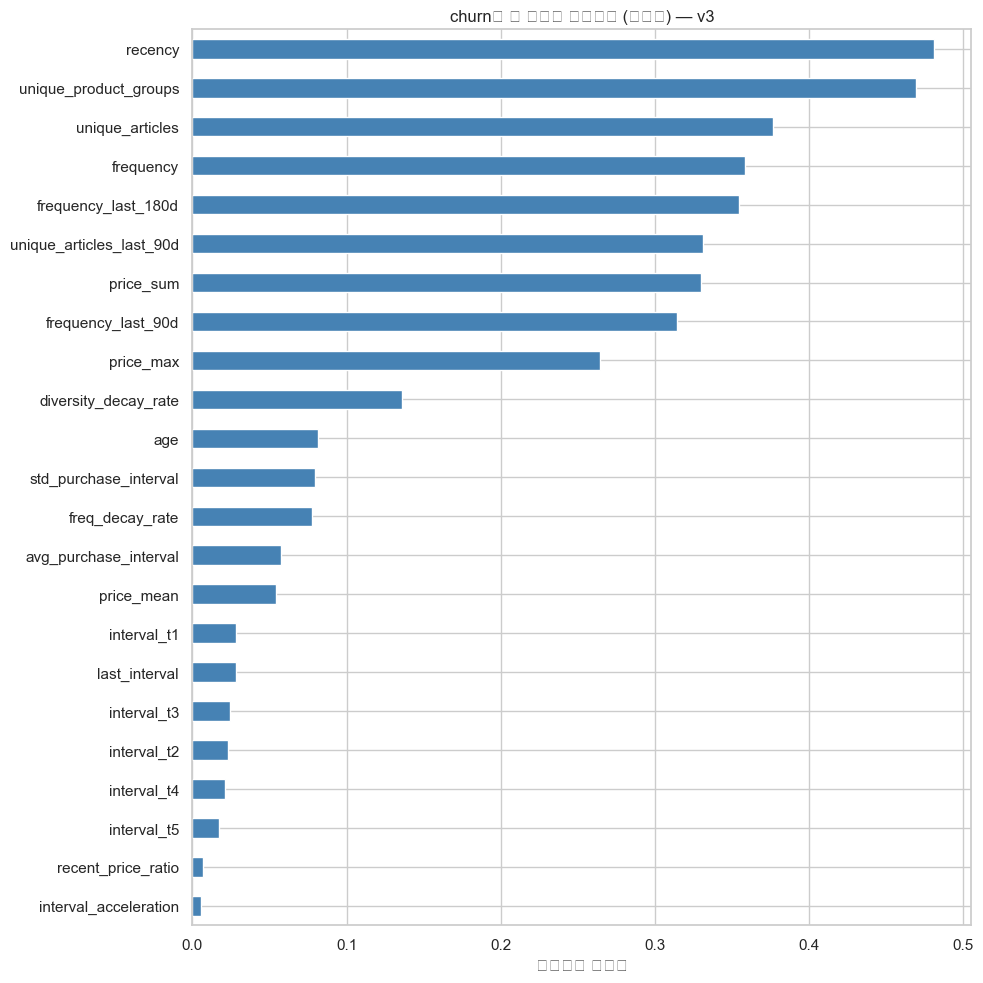

In [13]:
# churn과 상관관계 순위
churn_corr = correlation_matrix['churn'].drop('churn').abs().sort_values(ascending=False)

print('--- churn과 상관관계 순위 (절대값 기준) ---')
print(churn_corr.round(4).to_string())

plt.figure(figsize=(10, 10))
churn_corr.plot(kind='barh', color='steelblue')
plt.title('churn과 각 피처의 상관관계 (절대값) — v3')
plt.xlabel('상관계수 절대값')
plt.gca().invert_yaxis()
plt.tight_layout(); plt.show()


In [14]:
# 다중공선성 위험 변수 탐색 (0.7 이상)
high_corr_pairs = []
cols = correlation_matrix.columns.tolist()
for i in range(len(cols)):
    for j in range(i+1, len(cols)):
        if cols[i] == 'churn' or cols[j] == 'churn': continue
        val = abs(correlation_matrix.loc[cols[i], cols[j]])
        if val >= 0.7:
            high_corr_pairs.append((cols[i], cols[j], round(val, 4)))
high_corr_pairs.sort(key=lambda x: x[2], reverse=True)

print('--- 피처 간 상관관계 0.7 이상 쌍 ---')
for a, b, v in high_corr_pairs:
    print(f'  {a:<35} ↔ {b:<35} : {v}')


--- 피처 간 상관관계 0.7 이상 쌍 ---
  last_interval                       ↔ interval_t1                         : 1.0
  frequency                           ↔ unique_articles                     : 0.9823
  frequency_last_90d                  ↔ unique_articles_last_90d            : 0.9728
  frequency                           ↔ price_sum                           : 0.9519
  price_sum                           ↔ unique_articles                     : 0.9311
  avg_purchase_interval               ↔ std_purchase_interval               : 0.9114
  frequency_last_90d                  ↔ frequency_last_180d                 : 0.8433
  frequency                           ↔ frequency_last_180d                 : 0.8338
  frequency_last_180d                 ↔ unique_articles_last_90d            : 0.8262
  frequency_last_180d                 ↔ unique_articles                     : 0.822
  price_sum                           ↔ frequency_last_180d                 : 0.8019
  freq_decay_rate                     ↔ di

예상대로 last_interval ↔ interval_t1이 상관관계 1.0이에요. 완전히 동일한 정보예요.
전처리에서 last_interval을 제거하고 interval_t1만 남기면 돼요. 이미 EDA 결론 6-2에 "제거 검토"로 적어뒀으니까 전처리에서 실제로 drop하면 됩니다.
나머지 고상관 쌍들은 트리 모델이라 다중공선성 문제가 없어서 그대로 둬도 돼요. 참고로 정리하면:

## 6. EDA 종합 결론 및 전처리 전략 확정

### 6-1. 주요 인사이트 요약

**v1 → v2 → v3 피처 발전**
- v1 (RFM): recency, unique_product_groups 등 집계 통계량
- v2 (트렌드): freq_decay_rate, interval_acceleration 등 시간 변화율
- v3 (시퀀스): interval_t1~t5 — 압축 없이 구매 간격 원형 그대로

**시퀀스 피처에서 확인할 포인트**
- 이탈 고객의 interval_t1(가장 최근 간격)이 유지 고객보다 긴가?
- 이탈 고객의 간격이 t5→t1으로 갈수록 증가하는 패턴인가?
- interval_t2~t5 결측률이 이탈 고객에서 더 높은가?
→ 위 세 가지가 모두 Yes라면 시퀀스 피처가 유의미한 신호를 담고 있는 것

**last_interval ↔ interval_t1 다중공선성 주의**
- 두 컬럼이 동일한 정보일 가능성 높음
- 상관관계 0.9 이상이면 전처리에서 last_interval 제거 검토

### 6-2. 전처리 전략

| 항목 | 전략 |
| :--- | :--- |
| `FN`, `Active` | 0 대치 |
| `age` | 중앙값 대치 |
| `club_member_status`, `fashion_news_frequency` | UNKNOWN 대치 |
| `interval_t1~t5` | NaN 유지 (트리 모델 위임) |
| 기존 NaN 유지 피처 | v2와 동일 |
| `last_interval` vs `interval_t1` | 상관관계 확인 후 중복 시 제거 검토 |
| 범주형 인코딩 | 원-핫 인코딩 (`drop_first=False`) |
